# Recipe: A ring from an input file: images and SED

Reads the input file, changes nothing, runs it from Python and plots the SED and the images at 1.6 micron (scattered light) and 870 micron (thermal emission).

**Files:** `examples/debris_ring.nml`  
**Run time:** about 10 s  
**Manual:** Sect. 16.2 of `docs/manual/dms_manual.pdf`. The same code as a script: `python3 examples/recipes/ring_from_file.py`.

In [1]:
# Setup: this notebook lives in examples/recipes/ of the repository
import os, sys
if "REPO" not in globals():
    REPO = os.environ.get("DMS_REPO") or os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
os.chdir(REPO)                                        # input files and cache/ are relative to the root
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__)

DMS 2.2.1


In [2]:
m = dms.Model.from_file("examples/debris_ring.nml")
res = m.run()                                    # mode = 'both': images and the SED from them
print(f"f_d = {res.f_d:.2e},  tau_mean = {res.tau_mean:.2e}")
for il, lam in enumerate(res.wavelength):
    print(f"  {lam:6.1f} micron: thermal {res.sed['thermal'][il]:.3e} Jy, scattered {res.sed['scattered'][il]:.3e} Jy")

f_d = 8.09e-05,  tau_mean = 2.56e-04
     1.6 micron: thermal 1.039e-52 Jy, scattered 4.525e-04 Jy
    24.0 micron: thermal 1.003e-02 Jy, scattered 5.336e-06 Jy
    70.0 micron: thermal 8.872e-02 Jy, scattered 4.622e-07 Jy
   870.0 micron: thermal 1.842e-03 Jy, scattered 1.292e-09 Jy


In [3]:
# a full SED of the same model: change the run mode and the wavelengths only
sed = m.copy().update(run={"mode": "sed"},
                      wavelengths={"lambda_min": 0.5, "lambda_max": 2000.0, "n_lambda": 80}).run()

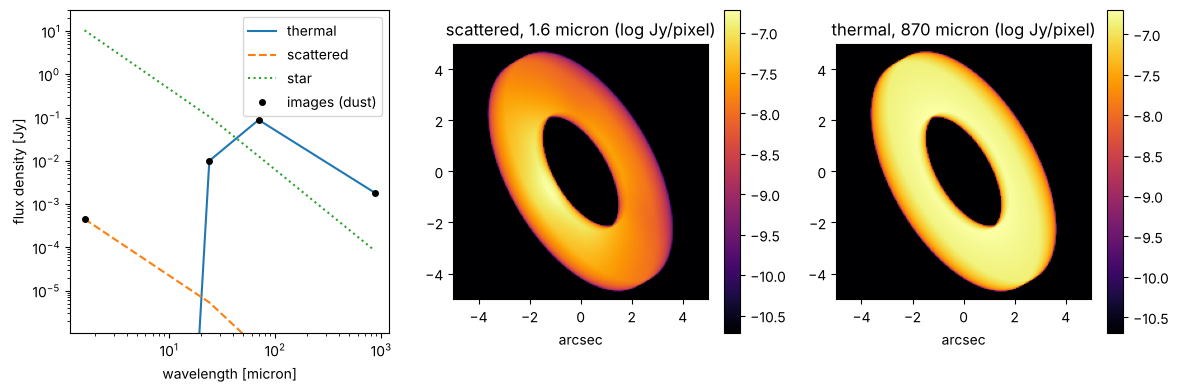

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
lam = sed.wavelength
for k, ls in (("thermal", "-"), ("scattered", "--"), ("star", ":")):
    ax[0].loglog(lam, sed.sed[k], ls, label=k)
ax[0].plot(res.wavelength, res.sed["thermal"] + res.sed["scattered"], "ko", ms=4, label="images (dust)")
ax[0].set_xlabel("wavelength [micron]"); ax[0].set_ylabel("flux density [Jy]"); ax[0].legend()
ax[0].set_ylim(1e-7 * sed.sed["star"].max(), 3 * sed.sed["star"].max())
half = res.pixel_arcsec * 201 / 2
for j, (name, il) in enumerate((("scattered", 0), ("thermal", 3)), start=1):
    img = res.image(name)[il]
    p = ax[j].imshow(np.log10(np.maximum(img, img.max() * 1e-4)), origin="lower", cmap="inferno",
                     extent=[-half, half, -half, half])
    ax[j].set_title(f"{name}, {lam[il]:g} micron (log Jy/pixel)")
    ax[j].set_xlabel("arcsec"); plt.colorbar(p, ax=ax[j])
plt.show()

**Result.** f_d = 8.1e-05; 89 mJy at 70 µm and 1.8 mJy at 870 µm. The dots are the fluxes of the four images (`mode = 'both'`); the lines are the full SED of the same model, obtained by changing only the run mode and the wavelengths. From the command line, `bin/dms examples/debris_ring.nml` writes the same model to `results/` (suffix `.ring`).